# Reading results of simulation

In [12]:
import pandas as pd
import numpy as np
import h5py as h5

import datetime as datetime
import matplotlib as mpl
import matplotlib.pyplot as plt


In [3]:
run_results = pd.read_hdf('../sim_data/mac_test/results_20230415_1307.h5')
run_results.set_index("int_length", inplace=True)

In [4]:
run_results.head()

,sim_number,clock_time
int_length,,
1000000.0,00003,107.458735
2500000.0,00003,273.403574
5000000.0,00003,541.987236
7500000.0,00003,817.452628
10000000.0,00003,1087.797607


sim_number
00003    Axes(0.125,0.11;0.775x0.77)
00004    Axes(0.125,0.11;0.775x0.77)
00005    Axes(0.125,0.11;0.775x0.77)
Name: clock_time, dtype: object

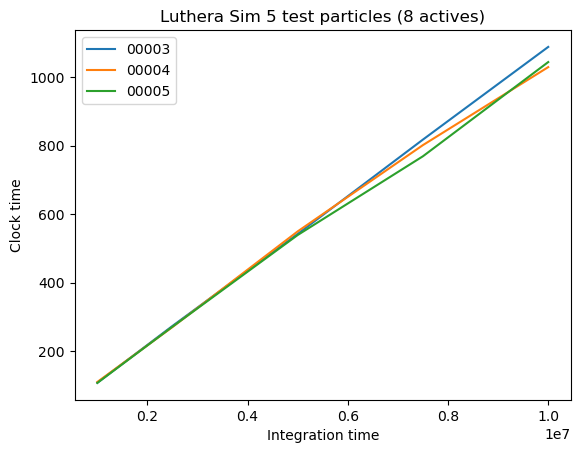

In [6]:
run_results.groupby("sim_number")["clock_time"].plot(legend=True, xlabel="Integration time", ylabel="Clock time", 
                                                     title="Luthera Sim 5 test particles (8 actives)")


In [7]:
avg_clock_time = run_results.groupby("int_length")["clock_time"].mean()

int_time = [float(int_time) for int_time in avg_clock_time.index]

lin_fit = np.polyfit(int_time, avg_clock_time,1)
reg_fun = np.poly1d(lin_fit)
print(reg_fun)

 
0.0001049 x + 9.072


In [8]:
print(reg_fun(int_time))
print(avg_clock_time)

print(f'Time to run 1.e6 {datetime.timedelta(seconds=reg_fun(1.e6))}')
print(f'Time to run 1.e7 {datetime.timedelta(seconds=reg_fun(1.e7))}')
print(f'Time to run 1.e8 {datetime.timedelta(seconds=reg_fun(1.e8))}')
print(f'Time to run 1.e9 {datetime.timedelta(seconds=reg_fun(1.e9))}')

print(f'Time to run 2.25e9 {datetime.timedelta(seconds=reg_fun(2.25e9))}')
print(f'Time to run 4.5e9 {datetime.timedelta(seconds=reg_fun(4.5e9))}')

[ 113.96121677  271.29448654  533.51660283  795.73871911 1057.96083539]
int_length
1000000.0      108.155760
2500000.0      271.621068
5000000.0      543.420321
7500000.0      795.851184
10000000.0    1053.423528
Name: clock_time, dtype: float64
Time to run 1.e6 0:01:53.961217
Time to run 1.e7 0:17:37.960835
Time to run 1.e8 2:54:57.957022
Time to run 1.e9 1 day, 5:08:17.918884
Time to run 2.25e9 2 days, 17:33:28.977025
Time to run 4.5e9 5 days, 11:06:48.881681


In [9]:
luthera = pd.read_hdf('luthera_eph.h5')

In [10]:
luthera.head()

,ast_name,X,Y,Z,VX,VY,VZ,sX,sY,sZ,sVX,sVY,sVZ
0,1303,3.359408,-0.452480,-1.186056,0.076525,0.487677,0.026783,8.701710e-08,3.175031e-07,4.760651e-08,4.385999e-08,1.156847e-08,1.581075e-08
1,11911,2.140391,1.429843,-0.830626,-0.361320,0.530306,-0.111506,3.203728e-07,4.665975e-07,1.742568e-07,8.816689e-08,6.423634e-08,5.606927e-08
2,16794,0.840324,-3.311674,0.736326,0.464880,0.160835,-0.142257,4.350451e-07,1.687924e-07,2.637303e-07,2.648034e-08,6.382716e-08,3.349555e-08
3,17840,2.750743,-0.702947,0.541571,0.211363,0.560981,-0.148605,1.709369e-07,4.277067e-07,1.138321e-07,8.366979e-08,2.448356e-08,1.830837e-08
4,26558,-2.853475,1.822653,0.823708,-0.324942,-0.380450,-0.104601,4.011603e-07,3.906963e-07,2.627875e-07,6.982964e-08,4.653161e-08,4.709016e-08


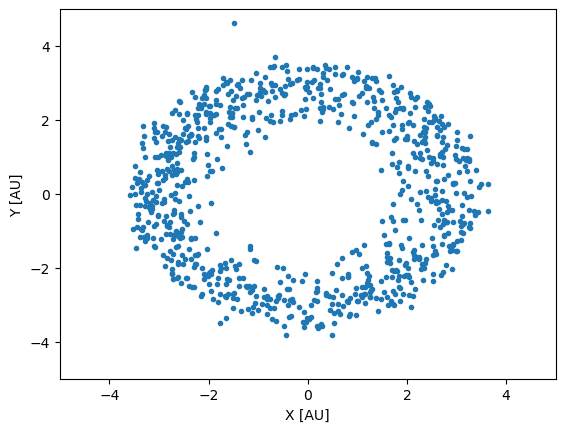

In [22]:
plt.scatter(data=luthera, x='X',y='Y', marker=".")
plt.xlim(-5, 5)
plt.ylim(-5, 5)
plt.xlabel('X [AU]')
plt.ylabel('Y [AU]')
plt.show()

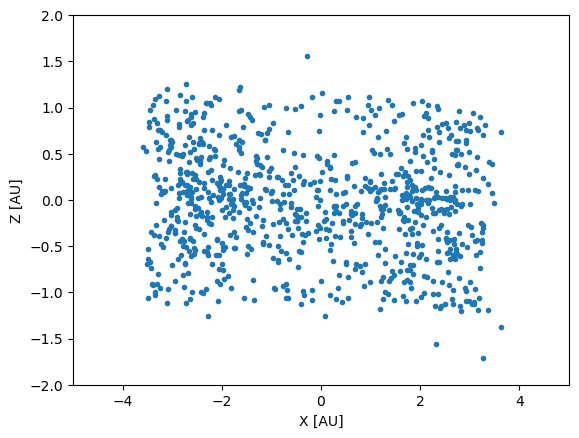

In [23]:
plt.scatter(data=luthera, x='X',y='Z', marker=".")
plt.ylim(-2, 2)
plt.xlim(-5, 5)
plt.xlabel('X [AU]')
plt.ylabel('Z [AU]')

plt.show()

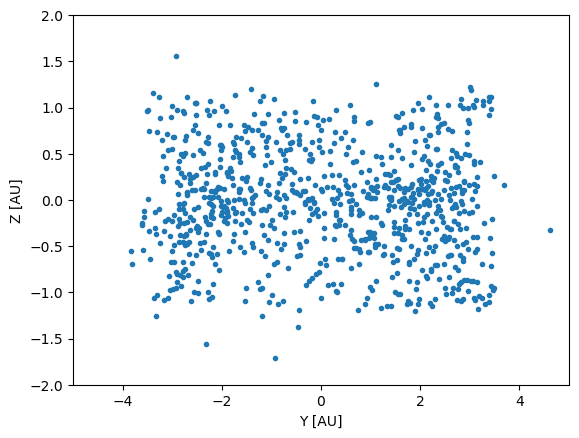

In [24]:
plt.scatter(data=luthera, x='Y',y='Z', marker=".")
plt.ylim(-2, 2)
plt.xlim(-5, 5)
plt.xlabel('Y [AU]')
plt.ylabel('Z [AU]')

plt.show()

In [21]:
luthera[(luthera.Y > 4.0)]

,ast_name,X,Y,Z,VX,VY,VZ,sX,sY,sZ,sVX,sVY,sVZ
854,2012 QD29,-1.478304,4.622391,-0.329345,-0.378571,-0.120554,0.004464,0.000003,8.221458e-07,0.000002,7.452620e-08,1.907042e-07,5.706045e-08
